In [4]:
# conda activate cellrank

import cellrank as cr
import scanpy as sc
import scvelo as scv
import anndata as ad

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

scv.settings.verbosity = 3

In [5]:
from cellrank.kernels.utils import RandomWalk  # path varies slightly by version

# veloVI

In [ ]:
adata_vv = ad.read_h5ad("/mnt/lareaulab/reliscu/projects/RNA_velocity/analyses/veloVI/janssens_2025_preprint/data/janssens_2025_CellRanger_Velocyto_counts_eLNP_veloVI_model_results.h5ad")

In [ ]:
scv.tl.velocity_pseudotime(adata_vv)

computing terminal states
    identified 4 regions of root cells and 1 region of end points .
    finished (0:00:02) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)


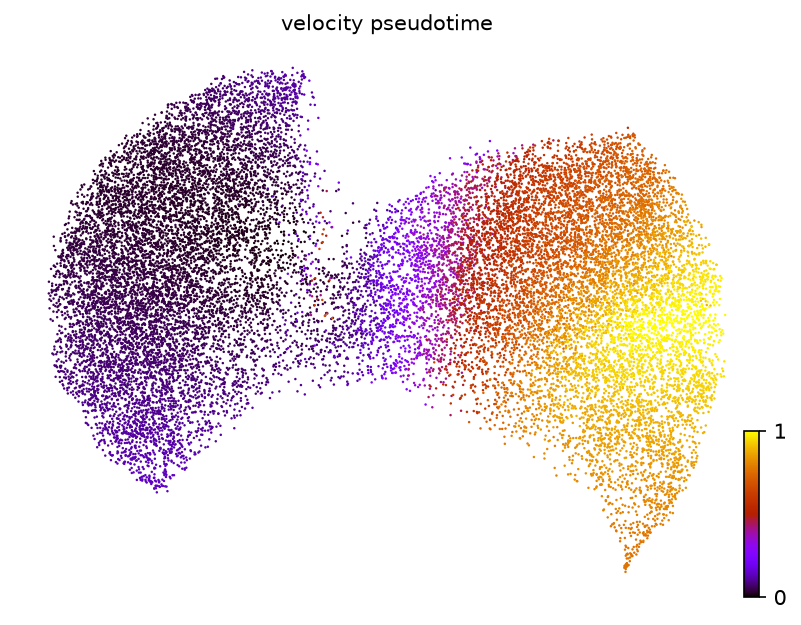

In [ ]:
scv.pl.scatter(
    adata_vv,
    color="velocity_pseudotime",
    cmap="gnuplot",
    dpi=150,
)

### Calc transition matrix

In [ ]:
vk_vv = cr.kernels.VelocityKernel(adata_vv)
vk_vv.compute_transition_matrix(model='deterministic')

In [ ]:
ck = cr.kernels.ConnectivityKernel(adata_vv)
ck.compute_transition_matrix()

INFO     Computing transition matrix based on adata.obsp['connectivities']                                         
INFO         Finish (0.03s)                                                                                        


ConnectivityKernel[n=21325, dnorm=True, key='connectivities']

In [ ]:
combined_kernel = 0.8 * vk_vv + 0.2 * ck

INFO     Projecting transition matrix onto 'umap'                                                                  
INFO     Adding `adata.obsm['T_fwd_umap']` (3.36s)                                                                 


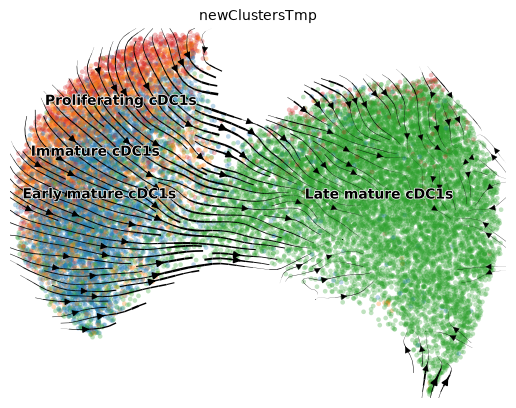

In [ ]:
vk_vv.plot_projection(color="newClustersTmp")

In [ ]:
combined_kernel.write_to_adata()

### Visualize paths

In [ ]:
print(adata.obs["Experimental_condition"].value_counts())

In [ ]:
t_mat_vv = adata_vv.obsp['T_fwd']

In [ ]:
start_cell = adata_vv.obs_names[10000]

In [ ]:
rw = RandomWalk(transition_matrix=t_mat_vv, adata=adata_vv, start_ixs=[start_cell]) 
sims = rw.simulate_many(n_sims=100, max_iter=100, seed=0, successive_hits=0)
walks_arr = np.stack(sims)

emb = adata_vv.obsm["X_umap"]
coords = emb[walks_arr]              # low dimensional embeddings for cells on each path
avg_trajectory = coords.mean(axis=0) # average embeddings over steps to get one path

INFO     Simulating 100 random walks of maximum length 100                                                         



























100%|██████████| 100/100 [00:03<00:00, 31.08sim/s]

INFO         Finish (3.24s)                                                                                        


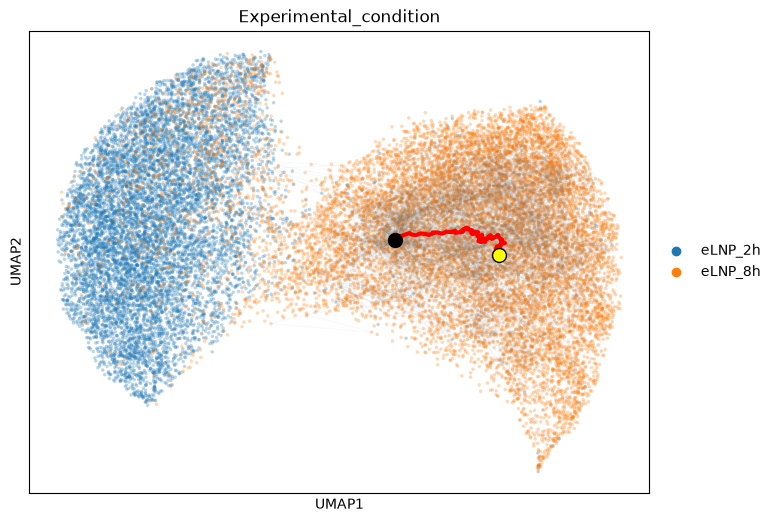

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
sc.pl.embedding(adata_vv, basis="umap", color="Experimental_condition", ax=ax, show=False, alpha=0.3, size=25)

# plot faint lines for individual walks
for i in range(coords.shape[0]):
    ax.plot(coords[i, :, 0], coords[i, :, 1], color="gray", alpha=0.05, linewidth=0.8, zorder=4)

# average, bold
ax.plot(avg_trajectory[:, 0], avg_trajectory[:, 1], color="red", linewidth=3, zorder=5)
ax.scatter(*avg_trajectory[0], color="black", s=100, zorder=6)
ax.scatter(*avg_trajectory[-1], color="yellow", edgecolor="black", s=100, zorder=6)

plt.show()

In [ ]:
latent_time = adata_vv.layers["latent_time_velovi"]

# Average latent time per cell, calculated using only the genes that show time-dependence
cell_avg_time = np.nanmean(latent_time, axis=1) 
adata_vv.obs['avg_latent_time'] = cell_avg_time

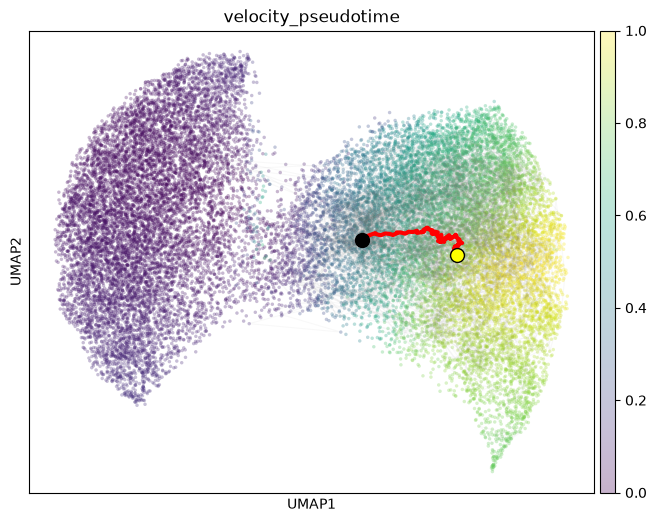

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))
sc.pl.embedding(adata_vv, basis="umap", color="velocity_pseudotime", ax=ax, show=False, alpha=0.3, size=25)

# plot faint lines for individual walks
for i in range(coords.shape[0]):
    ax.plot(coords[i, :, 0], coords[i, :, 1], color="gray", alpha=0.05, linewidth=0.8, zorder=4)

# average, bold
ax.plot(avg_trajectory[:, 0], avg_trajectory[:, 1], color="red", linewidth=3, zorder=5)
ax.scatter(*avg_trajectory[0], color="black", s=100, zorder=6)
ax.scatter(*avg_trajectory[-1], color="yellow", edgecolor="black", s=100, zorder=6)

plt.show()

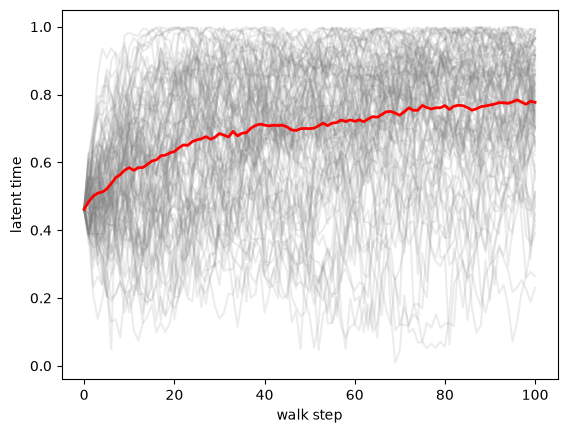

In [24]:
# Visualize latent time at each step

lt = adata_vv.obs["velocity_pseudotime"].values   # numpy array, aligned with adata's row order
walk_latent_times = lt[walks_arr]      # shape (n_sims, max_iter)

# individual walks, faint
for i in range(walk_latent_times.shape[0]):
    plt.plot(walk_latent_times[i], color="gray", alpha=0.15)

# average trend
plt.plot(np.nanmean(walk_latent_times, axis=0), color="red", linewidth=2)
plt.xlabel("walk step")
plt.ylabel("latent time")
plt.show()

# DeepVelo

In [26]:
adata_dv = ad.read_h5ad("/mnt/lareaulab/reliscu/projects/RNA_velocity/analyses/DeepVelo/janssens_2025_preprint/data/janssens_2025_CellRanger_Velocyto_counts_eLNP_DeepVelo_model_results.h5ad")

### Calc transition matrix

In [27]:
vk_dv = cr.kernels.VelocityKernel(adata_dv)
vk_dv.compute_transition_matrix(model='deterministic') # stochastic')

INFO     Computing transition matrix using 'deterministic' model                                                   





































































































































































100%|██████████| 21325/21325 [00:20<00:00, 1026.62cell/s]

INFO     Using `softmax_scale=6.7204`                                                                              

































































































100%|██████████| 21325/21325 [00:12<00:00, 1768.29cell/s]


INFO         Finish (32.96s)                                                                                       


VelocityKernel[n=21325, model='deterministic', similarity='correlation', softmax_scale=np.float64(6.72)]

In [28]:
ck = cr.kernels.ConnectivityKernel(adata_dv)
ck.compute_transition_matrix()

INFO     Computing transition matrix based on adata.obsp['connectivities']                                         
INFO         Finish (0.03s)                                                                                        


ConnectivityKernel[n=21325, dnorm=True, key='connectivities']

In [29]:
combined_kernel = 0.8 * vk_dv + 0.2 * ck

INFO     Projecting transition matrix onto 'umap'                                                                  
INFO     Adding `adata.obsm['T_fwd_umap']` (3.34s)                                                                 


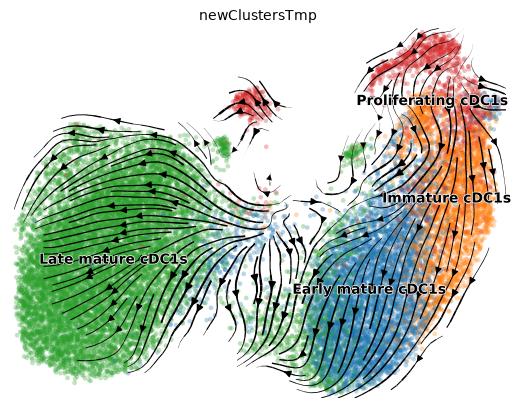

In [30]:
vk_dv.plot_projection(color="newClustersTmp")

In [31]:
combined_kernel.write_to_adata()
t_mat_dv = adata_dv.obsp['T_fwd']

In [32]:
start_cell = adata_dv.obs_names[10000]

In [33]:
rw = RandomWalk(transition_matrix=t_mat_dv, adata=adata_dv, start_ixs=[start_cell]) 
sims = rw.simulate_many(n_sims=100, max_iter=100, seed=0, successive_hits=0)
walks_arr = np.stack(sims)

emb = adata_dv.obsm["X_umap"]
coords = emb[walks_arr]              # low dimensional embeddings for cells on each path
avg_trajectory = coords.mean(axis=0) # average embeddings over steps to get one path

INFO     Simulating 100 random walks of maximum length 100                                                         























100%|██████████| 100/100 [00:03<00:00, 31.11sim/s]

INFO         Finish (3.22s)                                                                                        


In [82]:
adata_dv.obs['Experimental_condition'] = adata_dv.obs['Condition'].str.split(r" [0-9]").str[0]

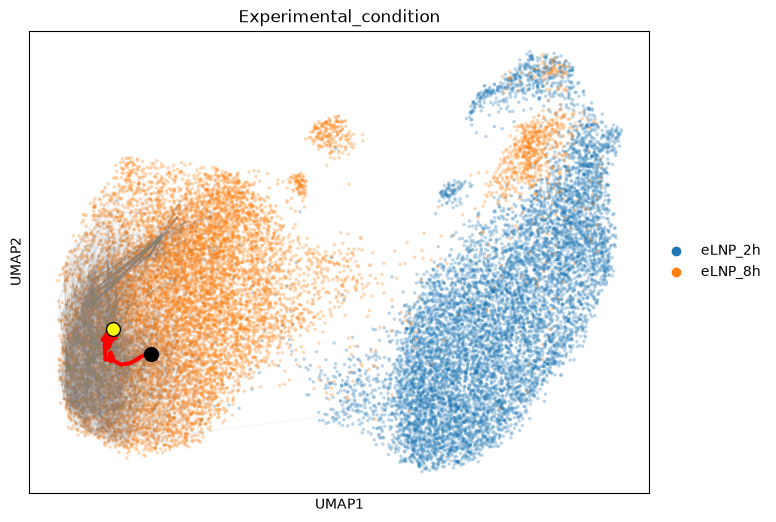

In [83]:
fig, ax = plt.subplots(figsize=(8, 6))
sc.pl.embedding(adata_dv, basis="umap", color="Experimental_condition", ax=ax, show=False, alpha=0.3, size=25)

# plot faint lines for individual walks
for i in range(coords.shape[0]):
    ax.plot(coords[i, :, 0], coords[i, :, 1], color="gray", alpha=0.05, linewidth=0.8, zorder=4)

# average, bold
ax.plot(avg_trajectory[:, 0], avg_trajectory[:, 1], color="red", linewidth=3, zorder=5)
ax.scatter(*avg_trajectory[0], color="black", s=100, zorder=6)
ax.scatter(*avg_trajectory[-1], color="yellow", edgecolor="black", s=100, zorder=6)

plt.show()

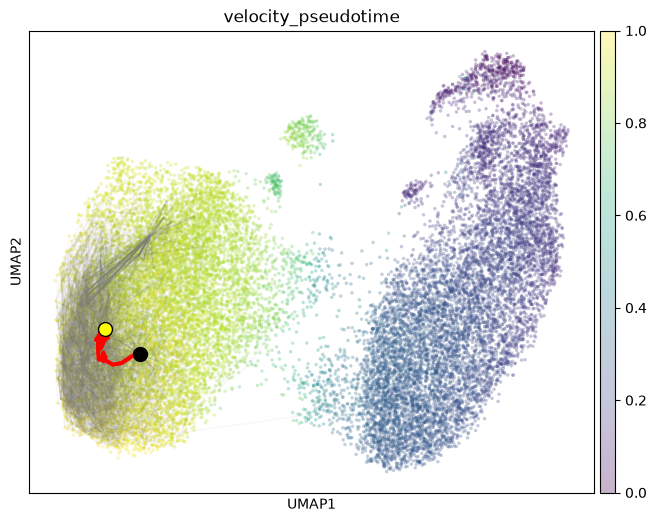

In [84]:
fig, ax = plt.subplots(figsize=(8, 6))
sc.pl.embedding(adata_dv, basis="umap", color="velocity_pseudotime", ax=ax, show=False, alpha=0.3, size=25)

# plot faint lines for individual walks
for i in range(coords.shape[0]):
    ax.plot(coords[i, :, 0], coords[i, :, 1], color="gray", alpha=0.05, linewidth=0.8, zorder=4)

# average, bold
ax.plot(avg_trajectory[:, 0], avg_trajectory[:, 1], color="red", linewidth=3, zorder=5)
ax.scatter(*avg_trajectory[0], color="black", s=100, zorder=6)
ax.scatter(*avg_trajectory[-1], color="yellow", edgecolor="black", s=100, zorder=6)

plt.show()

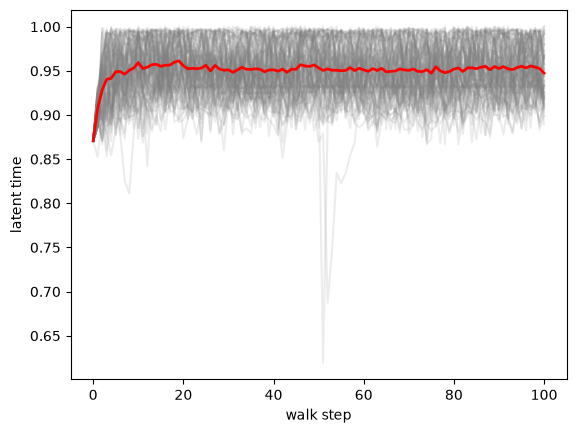

In [34]:
# Visualize latent time at each step

lt = adata_dv.obs["velocity_pseudotime"].values   # numpy array, aligned with adata's row order
walk_latent_times = lt[walks_arr]      # shape (n_sims, max_iter)

# individual walks, faint
for i in range(walk_latent_times.shape[0]):
    plt.plot(walk_latent_times[i], color="gray", alpha=0.15)

# average trend
plt.plot(np.nanmean(walk_latent_times, axis=0), color="red", linewidth=2)
plt.xlabel("walk step")
plt.ylabel("latent time")
plt.show()